# Human Activity Recognition: Complete Machine Learning Pipeline

**Course Project:** Practical Applications of AI & Machine Learning (PAIML Lab)  
**Project Title:** End-to-End Human Activity Recognition Pipeline  
**Students:** Kartikeya Jain & Ayush Yadav  
**Instructors:** Dr. Pruthwik Mishra & Dr. Praveen Chandaliya  

---

### Project Architecture & Implementation Roadmap

| Project Component | Notebook Section | Methodology & Description |
|---|---|---|
| **Data Ingestion** | Section 1 | Loading training and test partitions (>10,000 samples, 561 features, 6 classes) |
| **Exploratory Data Analysis** | Section 2 | Data integrity, class balance, ANOVA F-scores, feature correlations |
| **Data Preprocessing** | Section 3 | Standardization (`StandardScaler`) & volunteer-wise group partitioning |
| **Unsupervised Learning** | Section 4 | Natural cluster discovery via KMeans++ ($k=2, 6$) and density-based DBSCAN |
| **Baseline Modeling** | Section 5 | Benchmark evaluation across 5 classifiers on the full 561-feature space |
| **Feature Selection** | Section 6 | Sequential Feature Selection (Forward and Backward SFS to 15 features) |
| **Dimensionality Reduction** | Section 7 & 8 | Principal Component Analysis (PCA retaining 95% variance) & model re-evaluation |
| **Rigorous Evaluation** | Section 9 | Multi-metric evaluation (Accuracy, F1-macro, confusion matrices, 5-fold CV) |
| **Ensemble Learning** | Section 10 | Hard and soft voting meta-ensembles |
| **Conclusion & Findings** | Section 11 | Consolidated leaderboard, diagnostic confusion analysis, and final synthesis |


## 0. Imports and Settings

In [4]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import GroupKFold, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif, SequentialFeatureSelector
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, silhouette_score,
                             adjusted_rand_score, normalized_mutual_info_score)

warnings.filterwarnings("ignore")     # hide unnecessary warnings
sns.set_style("whitegrid")            # clean plot style

# ---------- Pipeline Configuration & Constants ----------
TARGET_COL = "ActivityName"     # label column ("ActivityName" has text labels like WALKING; fallback to "Activity")
SUBJECT_COL = "subject"          # volunteer-id column (used to avoid data leakage in cross-validation)
SHORTLIST_SIZE = 30              # features kept before forward/backward selection (keeps it fast)
N_SELECT = 15                    # features finally picked by forward and by backward selection
PCA_VARIANCE = 0.95              # PCA keeps components that explain 95% of the variance
CORR_THRESHOLD = 0.95            # of two features correlated above this, one is dropped
RANDOM_STATE = 42                # fixed seed so results are reproducible


## 1. Load Data

In [5]:
# Read dataset partitions
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")

# Ensure TARGET_COL resolves properly if ActivityName exists
if TARGET_COL not in train.columns:
    if "ActivityName" in train.columns:
        TARGET_COL = "ActivityName"
    elif "Activity" in train.columns:
        TARGET_COL = "Activity"

# Volunteer id of every training row (if the column exists)
HAS_SUBJECTS = SUBJECT_COL in train.columns
subj_train = train[SUBJECT_COL].values if HAS_SUBJECTS else None

# Features = sensor measurements only.
# Drop both label columns ('Activity' and 'ActivityName') plus the subject id
# to prevent string type issues in X_train and avoid 100% data leakage!
drop_cols = [c for c in [TARGET_COL, SUBJECT_COL, "Activity", "ActivityName"] if c in train.columns]
X_train = train.drop(columns=drop_cols)
X_test = test.drop(columns=drop_cols, errors="ignore")[X_train.columns]   # same columns, same order

# Convert activity names (text) into numbers 0..5, because models need numeric labels
le = LabelEncoder()
y_train = le.fit_transform(train[TARGET_COL].astype(str))
y_test = le.transform(test[TARGET_COL].astype(str))
class_names = [str(c) for c in le.classes_]
id_to_name = dict(enumerate(class_names))

print("Train shape:", X_train.shape, "| Test shape:", X_test.shape)
print("Total rows :", len(X_train) + len(X_test), "| Features:", X_train.shape[1], "| Classes:", len(class_names))
print("Classes    :", class_names)


Train shape: (7352, 561) | Test shape: (2947, 561)
Total rows : 10299 | Features: 561 | Classes: 6
Classes    : ['LAYING', 'SITTING', 'STANDING', 'WALKING', 'WALKING_DOWNSTAIRS', 'WALKING_UPSTAIRS']


## 2. Exploratory Data Analysis (EDA)

In [6]:
# ---------- Data quality ----------
print("All columns numeric?  ", all(pd.api.types.is_numeric_dtype(t) for t in X_train.dtypes))
print("Missing values (train):", int(X_train.isnull().sum().sum()))
print("Duplicate rows (train):", int(X_train.duplicated().sum()))

# ---------- Outliers: values more than 3 standard deviations away from the feature's mean ----------
z = (X_train - X_train.mean(numeric_only=True)) / X_train.std(numeric_only=True).replace(0, np.nan)
print(f"Average outlier % per feature: {(z.abs() > 3).mean().mean() * 100:.2f}%")

display(X_train.iloc[:, :6].describe().round(3))      # summary statistics of the first 6 features


All columns numeric?   True
Missing values (train): 0
Duplicate rows (train): 0
Average outlier % per feature: 0.98%


,tBodyAccmeanX,tBodyAccmeanY,tBodyAccmeanZ,tBodyAccstdX,tBodyAccstdY,tBodyAccstdZ
count,7352.000,7352.000,7352.000,7352.000,7352.000,7352.000
mean,0.274,-0.018,-0.109,-0.605,-0.511,-0.605
std,0.070,0.041,0.057,0.449,0.503,0.419
min,-1.000,-1.000,-1.000,-1.000,-1.000,-1.000
25%,0.263,-0.025,-0.121,-0.993,-0.978,-0.980
50%,0.277,-0.017,-0.109,-0.946,-0.852,-0.859
75%,0.288,-0.011,-0.098,-0.243,-0.034,-0.262
max,1.000,1.000,1.000,1.000,0.916,1.000


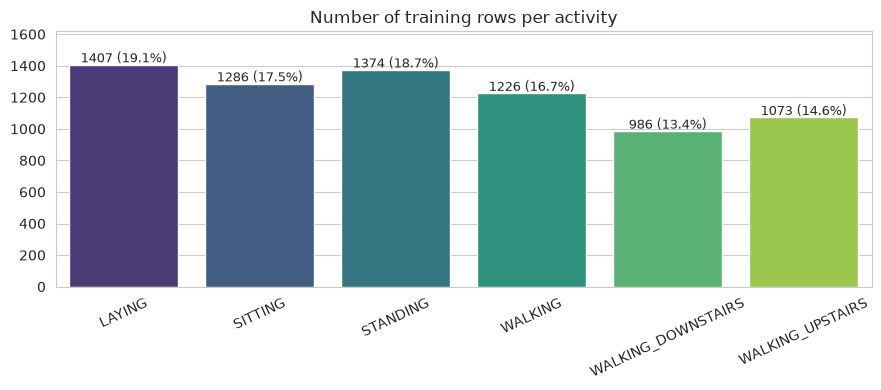

In [7]:
# ---------- Class distribution (are the activities balanced?) ----------
counts = pd.Series(y_train).map(id_to_name).value_counts().reindex(class_names)

plt.figure(figsize=(9, 4))
ax = sns.barplot(x=counts.index, y=counts.values, hue=counts.index, palette="viridis", legend=False)
for i, v in enumerate(counts.values):
    ax.text(i, v + 15, f"{v} ({v / len(y_train) * 100:.1f}%)", ha="center", fontsize=9)
plt.title("Number of training rows per activity")
plt.xticks(rotation=25)
plt.xlabel("")
plt.ylim(0, counts.max() * 1.15)
plt.tight_layout()
plt.show()


Top 4 features: ['fBodyAccJerkentropyX', 'tGravityAccmeanX', 'tGravityAccminX', 'fBodyAccJerkentropyY']


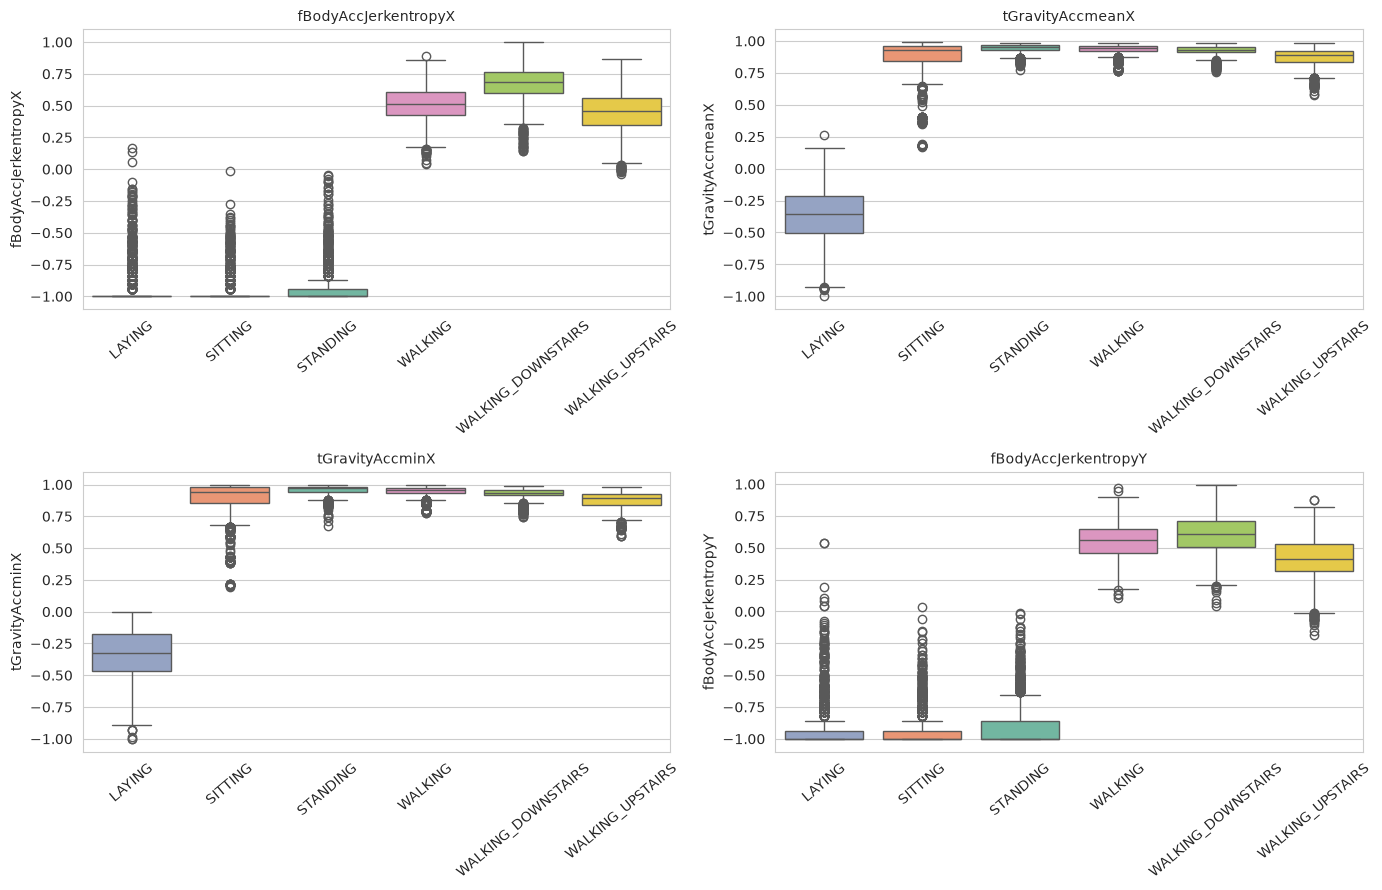

In [8]:
# ---------- Boxplots of the 4 features that separate the activities best ----------
# A high ANOVA F-score means "this feature has very different values for different activities"
f_scores, _ = f_classif(X_train, y_train)
top_features = X_train.columns[np.argsort(np.nan_to_num(f_scores))[::-1][:4]].tolist()
print("Top 4 features:", top_features)

plot_df = X_train[top_features].copy()
plot_df["Activity"] = pd.Series(y_train).map(id_to_name).values

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, feat in zip(axes.ravel(), top_features):
    sns.boxplot(data=plot_df, x="Activity", y=feat, order=class_names, hue="Activity", palette="Set2", legend=False, ax=ax)
    ax.set_title(feat, fontsize=10)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=40)
plt.tight_layout()
plt.show()


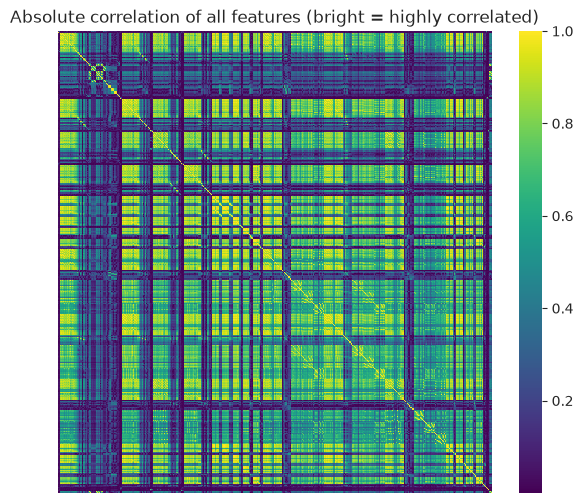

Feature pairs with correlation > 0.7: 36564 of 157080 (23.3%)
Feature pairs with correlation > 0.9: 8206 of 157080 (5.2%)


In [9]:
# ---------- Correlation between features ----------
# Many features describe the same signal, so they move together. This is the reason we need feature selection and PCA.
corr_abs = X_train.corr().abs()

plt.figure(figsize=(7, 6))
sns.heatmap(corr_abs, cmap="viridis", xticklabels=False, yticklabels=False)
plt.title("Absolute correlation of all features (bright = highly correlated)")
plt.show()

# Count strongly correlated pairs (each pair counted once)
upper = corr_abs.where(np.triu(np.ones(corr_abs.shape, dtype=bool), k=1))
total_pairs = int(upper.notna().sum().sum())
for t in [0.7, 0.9]:
    n = int((upper > t).sum().sum())
    print(f"Feature pairs with correlation > {t}: {n} of {total_pairs} ({n / total_pairs * 100:.1f}%)")

## 3. Preprocessing

`StandardScaler` puts all features on the same scale. It is learned on the **training data only** and then applied to the test data (this avoids data leakage).

In [10]:
scaler = StandardScaler()
X_train_s = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns)
X_test_s = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns)

# Cross-validation splits. The same volunteer appears in many rows, so GroupKFold keeps each volunteer
# in only ONE fold. Otherwise the model "recognises the person" and the scores look too good.
def make_cv_splits(n_splits):
    if HAS_SUBJECTS:
        return list(GroupKFold(n_splits=n_splits).split(X_train_s, y_train, groups=subj_train))
    return list(StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE).split(X_train_s, y_train))

## 4. Unsupervised Learning (KMeans++ and DBSCAN)

The activity labels are **ignored** here. The algorithms group the rows on their own, and then we check whether the groups match the real activities.

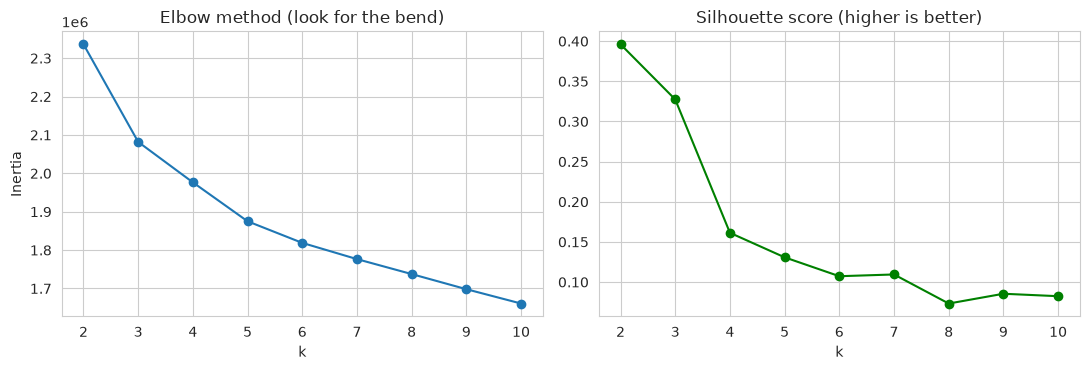

Best k by silhouette score: 2


In [11]:
# ---------- KMeans++: elbow method and silhouette score to choose k ----------
k_values = list(range(2, 11))
inertias, silhouettes = [], []
for k in k_values:
    km = KMeans(n_clusters=k, init="k-means++", n_init=3, random_state=RANDOM_STATE)
    labels = km.fit_predict(X_train_s)
    inertias.append(km.inertia_)                       # how tight the clusters are (lower = tighter)
    silhouettes.append(silhouette_score(X_train_s, labels, sample_size=3000, random_state=RANDOM_STATE))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(k_values, inertias, "o-")
axes[0].set_title("Elbow method (look for the bend)")
axes[0].set_xlabel("k")
axes[0].set_ylabel("Inertia")
axes[1].plot(k_values, silhouettes, "o-", color="green")
axes[1].set_title("Silhouette score (higher is better)")
axes[1].set_xlabel("k")
plt.tight_layout()
plt.show()
print("Best k by silhouette score:", k_values[int(np.argmax(silhouettes))])

KMeans cluster,0,1
Real group,,
Dynamic (walking),8,3277
Static (sit/stand/lay),4055,12


Adjusted Rand Index   : 0.42
Normalized Mutual Info: 0.559


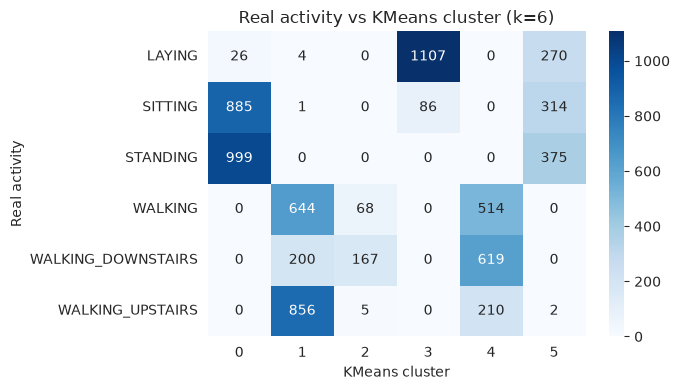

In [12]:
# ---------- KMeans with k=2: static vs dynamic activities ----------
# Dynamic = activities with "WALKING" in the name, static = sitting, standing, laying
is_dynamic = np.array(["WALKING" in str(c) for c in class_names])[y_train]
real_group = np.where(is_dynamic, "Dynamic (walking)", "Static (sit/stand/lay)")

km2 = KMeans(n_clusters=2, init="k-means++", n_init=10, random_state=RANDOM_STATE).fit(X_train_s)
display(pd.crosstab(pd.Series(real_group, name="Real group"), pd.Series(km2.labels_, name="KMeans cluster")))

# ---------- KMeans with k=6: do clusters match the 6 real activities? ----------
# ARI and NMI: 1 means perfect match with the real labels, 0 means random
km6 = KMeans(n_clusters=6, init="k-means++", n_init=10, random_state=RANDOM_STATE).fit(X_train_s)
print("Adjusted Rand Index   :", round(adjusted_rand_score(y_train, km6.labels_), 3))
print("Normalized Mutual Info:", round(normalized_mutual_info_score(y_train, km6.labels_), 3))

ct6 = pd.crosstab(pd.Series(y_train).map(id_to_name).rename("Real activity"),
                  pd.Series(km6.labels_, name="KMeans cluster")).reindex(class_names)
plt.figure(figsize=(7, 4))
sns.heatmap(ct6, annot=True, fmt="d", cmap="Blues")
plt.title("Real activity vs KMeans cluster (k=6)")
plt.tight_layout()
plt.show()


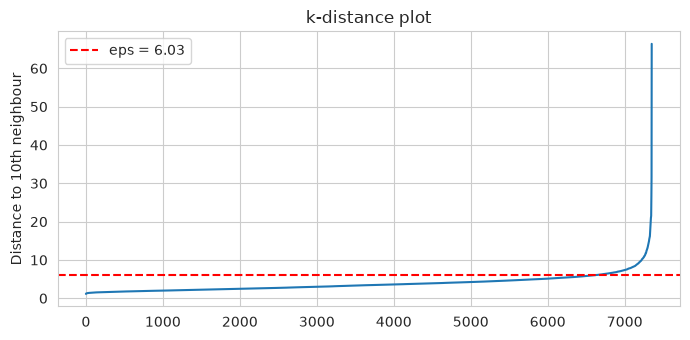

DBSCAN found 5 clusters and 371 noise points
Adjusted Rand Index: 0.32


In [13]:
# ---------- DBSCAN (density-based, marks isolated points as noise = -1) ----------
# DBSCAN struggles in 500+ dimensions, so we run it on a small 10-component PCA version of the data
X_train_pca10 = PCA(n_components=10, random_state=RANDOM_STATE).fit_transform(X_train_s)

# Choose eps with a k-distance plot: distance of every point to its 10th nearest neighbour, sorted
min_samples = 10
dist, _ = NearestNeighbors(n_neighbors=min_samples).fit(X_train_pca10).kneighbors(X_train_pca10)
k_dist = np.sort(dist[:, -1])
eps_value = float(np.percentile(k_dist, 90))          # 90th percentile of 10th nearest-neighbor distances

plt.figure(figsize=(7, 3.5))
plt.plot(k_dist)
plt.axhline(eps_value, color="red", linestyle="--", label=f"eps = {eps_value:.2f}")
plt.title("k-distance plot")
plt.ylabel("Distance to 10th neighbour")
plt.legend()
plt.tight_layout()
plt.show()

db_labels = DBSCAN(eps=eps_value, min_samples=min_samples).fit_predict(X_train_pca10)
n_clusters = len(set(db_labels)) - (1 if -1 in db_labels else 0)
print(f"DBSCAN found {n_clusters} clusters and {(db_labels == -1).sum()} noise points")
print("Adjusted Rand Index:", round(adjusted_rand_score(y_train, db_labels), 3))
# Note: Increasing eps produces fewer, broader clusters; decreasing eps identifies more localized clusters and increases noise points.

## 5. Baseline Models on Full Feature Space

In this section, we establish baseline benchmark performance across five distinct classifiers using the entire 561-dimensional sensor space. Subsequent sections evaluate whether reduced feature representations can match or exceed these reference scores.


In [14]:
def get_models():
    # Returns fresh, untrained models every time it is called
    return {
        "Logistic Regression": LogisticRegression(max_iter=500, random_state=RANDOM_STATE),
        "KNN": KNeighborsClassifier(n_neighbors=5),
        "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
        "Random Forest": RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1),
        "SVM": SVC(kernel="rbf", random_state=RANDOM_STATE),
    }

results, predictions = {}, {}      # every experiment is stored here for the final comparison

def record(feature_set, model_name, y_pred, n_features, train_time):
    # Compute all metrics on the test set and store them
    results[(feature_set, model_name)] = {
        "Feature Set": feature_set, "Model": model_name, "Num Features": n_features,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (macro)": precision_score(y_test, y_pred, average="macro", zero_division=0),
        "Recall (macro)": recall_score(y_test, y_pred, average="macro", zero_division=0),
        "F1 (macro)": f1_score(y_test, y_pred, average="macro", zero_division=0),
        "Train Time (s)": train_time,
    }
    predictions[(feature_set, model_name)] = y_pred
    r = results[(feature_set, model_name)]
    print(f"{model_name:<26} accuracy={r['Accuracy']:.4f}   F1={r['F1 (macro)']:.4f}   time={train_time:.1f}s")

def run_all_models(feature_set, Xtr, Xte):
    # Train and evaluate all 5 models on the given feature set
    print(f"\n=== {feature_set} ({Xtr.shape[1]} features) ===")
    for name, model in get_models().items():
        start = time.time()
        model.fit(Xtr, y_train)
        record(feature_set, name, model.predict(Xte), Xtr.shape[1], time.time() - start)

run_all_models("All Features", X_train_s, X_test_s)


=== All Features (561 features) ===
Logistic Regression        accuracy=0.9552   F1=0.9551   time=9.7s
KNN                        accuracy=0.8836   F1=0.8805   time=0.2s
Decision Tree              accuracy=0.8622   F1=0.8595   time=3.1s
Random Forest              accuracy=0.9267   F1=0.9251   time=0.8s
SVM                        accuracy=0.9518   F1=0.9511   time=2.4s


## 6. Feature Selection: Sequential Forward & Backward Selection

To identify the most discriminative subset of sensor features and eliminate collinear redundancy:
- **Forward Selection:** Iteratively incorporates features one-by-one that yield the highest cross-validation score.
- **Backward Selection:** Starts with candidate features and iteratively prunes the least informative attributes.

To ensure computational tractability over 561 dimensions, we filter extreme pairwise correlations ($>0.95$) and shortlist the top 30 features via ANOVA F-statistic before running 3-fold cross-validated Sequential Feature Selection (SFS).


In [15]:
# ---------- Step 1: shortlist ----------
# (a) drop features that are highly correlated with an earlier feature (they carry the same information)
corr = X_train_s.corr().abs()
upper_tri = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
keep = [c for c in corr.columns if not (upper_tri[c] > CORR_THRESHOLD).any()]
print(f"After correlation filter: {len(keep)} features (from {X_train.shape[1]})")

# (b) keep the top SHORTLIST_SIZE features by ANOVA F-score
skb = SelectKBest(f_classif, k=min(SHORTLIST_SIZE, len(keep))).fit(X_train_s[keep], y_train)
shortlist = X_train_s[keep].columns[skb.get_support()].tolist()
print("Shortlist size:", len(shortlist))

# ---------- Step 2: forward and backward selection on the shortlist ----------
n_select = min(N_SELECT, len(shortlist) - 1)
cv3 = make_cv_splits(3)

def run_sfs(direction):
    sfs = SequentialFeatureSelector(
        LogisticRegression(max_iter=300, random_state=RANDOM_STATE),    # fast model keeps this step quick
        n_features_to_select=n_select, direction=direction,             # "forward" or "backward"
        scoring="accuracy", cv=cv3, n_jobs=-1)
    start = time.time()
    sfs.fit(X_train_s[shortlist], y_train)
    print(f"{direction.capitalize()} selection took {time.time() - start:.0f}s")
    return X_train_s[shortlist].columns[sfs.get_support()].tolist()

forward_features = run_sfs("forward")
backward_features = run_sfs("backward")

print("\nForward-selected :", forward_features)
print("\nBackward-selected:", backward_features)
print(f"\nChosen by BOTH methods: {len(set(forward_features) & set(backward_features))} of {n_select}")

After correlation filter: 253 features (from 561)
Shortlist size: 30
Forward selection took 26s
Backward selection took 68s

Forward-selected : ['tBodyAccstdX', 'tBodyAccentropyX', 'tBodyAccentropyY', 'tGravityAccmeanX', 'tGravityAccmeanY', 'tGravityAccenergyY', 'tBodyAccJerkstdZ', 'tBodyAccJerkenergyX', 'tBodyAccJerkentropyX', 'tBodyGyrostdX', 'tBodyGyromaxX', 'tBodyGyrominX', 'tBodyAccJerkMagmin', 'tBodyGyroMagenergy', 'fBodyAccJerkmeanFreqX']

Backward-selected: ['tBodyAccstdX', 'tBodyAccentropyX', 'tBodyAccentropyZ', 'tGravityAccmeanX', 'tGravityAccmeanY', 'tGravityAccenergyY', 'tBodyAccJerkstdZ', 'tBodyAccJerkentropyX', 'tBodyGyrostdX', 'tBodyGyrostdY', 'tBodyGyromaxX', 'tBodyGyromaxZ', 'tBodyGyrominX', 'tBodyGyrominY', 'tBodyGyroMagenergy']

Chosen by BOTH methods: 11 of 15


In [16]:
# Train all 5 models again using only the selected features
run_all_models("Forward Selection", X_train_s[forward_features], X_test_s[forward_features])
run_all_models("Backward Selection", X_train_s[backward_features], X_test_s[backward_features])


=== Forward Selection (15 features) ===
Logistic Regression        accuracy=0.8592   F1=0.8570   time=0.2s
KNN                        accuracy=0.8164   F1=0.8124   time=0.1s
Decision Tree              accuracy=0.7971   F1=0.7907   time=0.1s
Random Forest              accuracy=0.8510   F1=0.8479   time=0.2s
SVM                        accuracy=0.8714   F1=0.8693   time=0.5s

=== Backward Selection (15 features) ===
Logistic Regression        accuracy=0.8673   F1=0.8662   time=0.2s
KNN                        accuracy=0.8191   F1=0.8145   time=0.1s
Decision Tree              accuracy=0.8107   F1=0.8052   time=0.1s
Random Forest              accuracy=0.8422   F1=0.8388   time=0.2s
SVM                        accuracy=0.8751   F1=0.8731   time=0.5s


## 7. Dimensionality Reduction: Principal Component Analysis (PCA)

We apply Principal Component Analysis (PCA) to project the correlated accelerometer and gyroscope features onto an orthogonal coordinate system, retaining the minimum number of principal components required to preserve 95% of total variance.


102 components explain 95% of the variance (instead of 561 features)


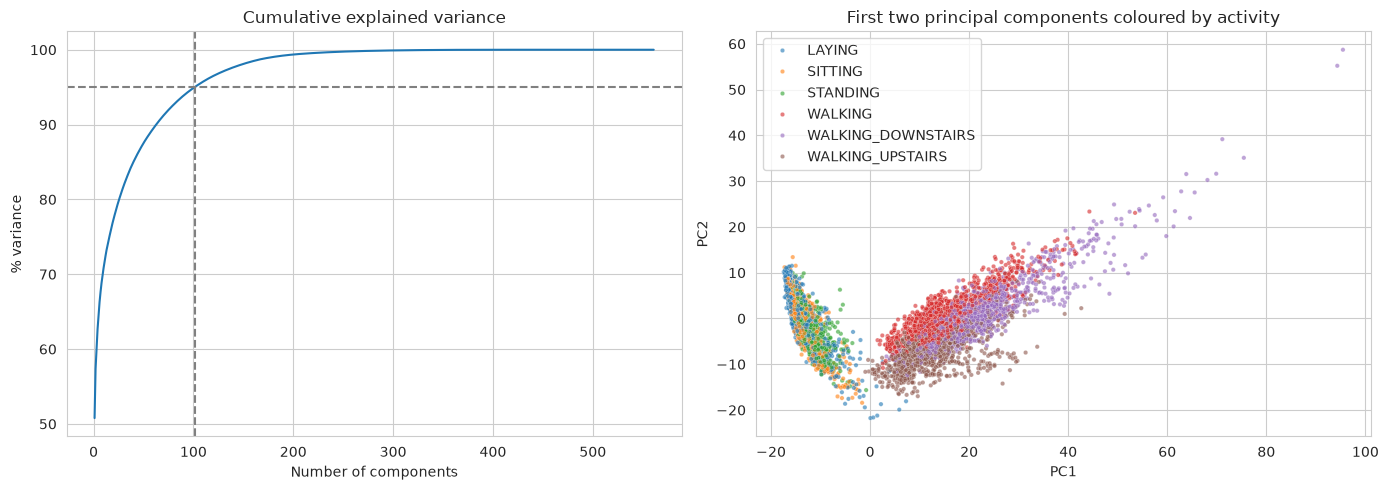

In [17]:
# Fit PCA with all components just to see how the explained variance builds up
cum_var = np.cumsum(PCA(random_state=RANDOM_STATE).fit(X_train_s).explained_variance_ratio_)
n_pca = int(np.argmax(cum_var >= PCA_VARIANCE) + 1)      # smallest number of components reaching 95%
print(f"{n_pca} components explain {PCA_VARIANCE * 100:.0f}% of the variance (instead of {X_train.shape[1]} features)")

# Final PCA: learned on the training data only, then applied to both train and test
pca = PCA(n_components=n_pca, random_state=RANDOM_STATE)
X_train_pca = pca.fit_transform(X_train_s)
X_test_pca = pca.transform(X_test_s)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
# Left: cumulative explained variance
axes[0].plot(range(1, len(cum_var) + 1), cum_var * 100)
axes[0].axhline(PCA_VARIANCE * 100, color="gray", linestyle="--")
axes[0].axvline(n_pca, color="gray", linestyle="--")
axes[0].set_title("Cumulative explained variance")
axes[0].set_xlabel("Number of components")
axes[0].set_ylabel("% variance")
# Right: the data in 2D using the first two components
sns.scatterplot(x=X_train_pca[:, 0], y=X_train_pca[:, 1], hue=pd.Series(y_train).map(id_to_name).values,
                hue_order=class_names, palette="tab10", s=10, alpha=0.6, ax=axes[1])
axes[1].set_title("First two principal components coloured by activity")
axes[1].set_xlabel("PC1")
axes[1].set_ylabel("PC2")
plt.tight_layout()
plt.show()

## 8. Models on PCA Features

In [18]:
run_all_models("PCA", X_train_pca, X_test_pca)


=== PCA (102 features) ===
Logistic Regression        accuracy=0.9311   F1=0.9298   time=6.3s
KNN                        accuracy=0.8768   F1=0.8745   time=0.1s
Decision Tree              accuracy=0.7533   F1=0.7501   time=0.6s
Random Forest              accuracy=0.8816   F1=0.8775   time=0.4s
SVM                        accuracy=0.9376   F1=0.9362   time=0.7s


## 9. Evaluation

All metrics are on the unseen test set. **Precision:** when the model predicts an activity, how often is it right? **Recall:** of all real rows of an activity, how many were found? **F1:** balance of both (macro = every class counts equally).

ACCURACY


Feature Set,All Features,Forward Selection,Backward Selection,PCA
Model,,,,
Logistic Regression,0.9552,0.8592,0.8673,0.9311
KNN,0.8836,0.8164,0.8191,0.8768
Decision Tree,0.8622,0.7971,0.8107,0.7533
Random Forest,0.9267,0.8510,0.8422,0.8816
SVM,0.9518,0.8714,0.8751,0.9376


MACRO F1-SCORE


Feature Set,All Features,Forward Selection,Backward Selection,PCA
Model,,,,
Logistic Regression,0.9551,0.8570,0.8662,0.9298
KNN,0.8805,0.8124,0.8145,0.8745
Decision Tree,0.8595,0.7907,0.8052,0.7501
Random Forest,0.9251,0.8479,0.8388,0.8775
SVM,0.9511,0.8693,0.8731,0.9362


TRAINING TIME (seconds)


Feature Set,All Features,Forward Selection,Backward Selection,PCA
Model,,,,
Logistic Regression,9.68,0.18,0.15,6.32
KNN,0.18,0.10,0.09,0.09
Decision Tree,3.08,0.07,0.07,0.59
Random Forest,0.82,0.23,0.24,0.43
SVM,2.43,0.50,0.52,0.67


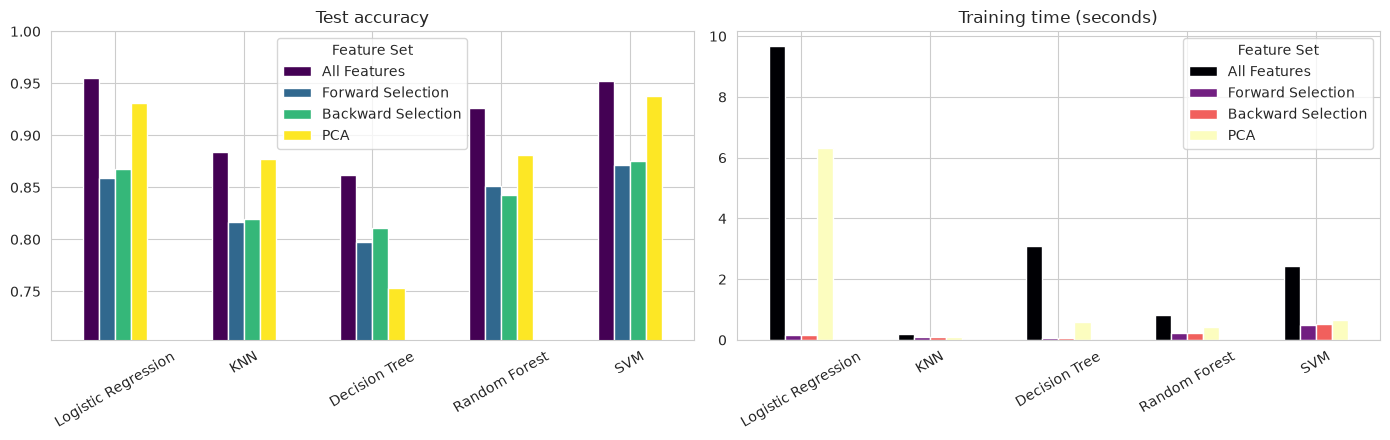

In [19]:
FEATURE_SETS = ["All Features", "Forward Selection", "Backward Selection", "PCA"]
MODEL_ORDER = list(get_models().keys())

df = pd.DataFrame(list(results.values()))
df = df[df["Feature Set"].isin(FEATURE_SETS)]          # the 5 single models only (ensembles come later)

def table(metric):
    return df.pivot(index="Model", columns="Feature Set", values=metric).reindex(MODEL_ORDER)[FEATURE_SETS]

acc_table, f1_table, time_table = table("Accuracy"), table("F1 (macro)"), table("Train Time (s)")
print("ACCURACY");        display(acc_table.round(4))
print("MACRO F1-SCORE");  display(f1_table.round(4))
print("TRAINING TIME (seconds)"); display(time_table.round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
acc_table.plot(kind="bar", ax=axes[0], colormap="viridis", edgecolor="white")
axes[0].set_title("Test accuracy")
axes[0].set_ylim(max(0, acc_table.min().min() - 0.05), 1.0)
time_table.plot(kind="bar", ax=axes[1], colormap="magma", edgecolor="white")
axes[1].set_title("Training time (seconds)")
for ax in axes:
    ax.tick_params(axis="x", rotation=30)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

Best single model: Logistic Regression on 'All Features'  (accuracy=0.9552, F1=0.9551)


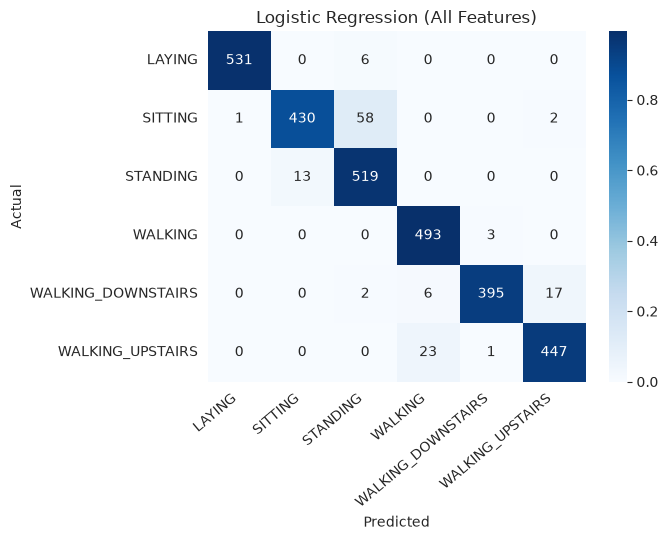

                    precision    recall  f1-score   support

            LAYING      0.998     0.989     0.993       537
           SITTING      0.971     0.876     0.921       491
          STANDING      0.887     0.976     0.929       532
           WALKING      0.944     0.994     0.969       496
WALKING_DOWNSTAIRS      0.990     0.940     0.965       420
  WALKING_UPSTAIRS      0.959     0.949     0.954       471

          accuracy                          0.955      2947
         macro avg      0.958     0.954     0.955      2947
      weighted avg      0.957     0.955     0.955      2947

SITTING <-> STANDING mistakes: 71 out of 132 total mistakes (53.8%)


In [20]:
def plot_confusion(y_true, y_pred, title):
    # Rows = actual activity, columns = predicted activity. Numbers are counts, colour is the row percentage.
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(7, 5.5))
    sns.heatmap(cm / cm.sum(axis=1, keepdims=True), annot=cm, fmt="d", cmap="Blues",
                xticklabels=class_names, yticklabels=class_names)
    plt.title(title)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.xticks(rotation=40, ha="right")
    plt.tight_layout()
    plt.show()
    return cm

# Best single model by macro F1
best = df.sort_values("F1 (macro)", ascending=False).iloc[0]
key = (best["Feature Set"], best["Model"])
print(f"Best single model: {key[1]} on '{key[0]}'  (accuracy={best['Accuracy']:.4f}, F1={best['F1 (macro)']:.4f})")

cm = plot_confusion(y_test, predictions[key], f"{key[1]} ({key[0]})")
print(classification_report(y_test, predictions[key], target_names=class_names, digits=3))

# Share of the mistakes that are SITTING <-> STANDING confusion
if "SITTING" in class_names and "STANDING" in class_names:
    s, t = class_names.index("SITTING"), class_names.index("STANDING")
    total_mistakes = cm.sum() - np.trace(cm)
    sit_stand_mistakes = cm[s, t] + cm[t, s]
    if total_mistakes > 0:
        print(f"SITTING <-> STANDING mistakes: {sit_stand_mistakes} out of {total_mistakes} total mistakes ({sit_stand_mistakes / total_mistakes * 100:.1f}%)")
    else:
        print("Zero mistakes on the test set!")


In [21]:
# ---------- Cross-validation (5 folds, volunteer-wise) ----------
# A single train/test split can be lucky or unlucky. The pipeline (scale -> PCA -> model) is re-fitted
# inside every fold, so nothing leaks from the validation fold.
cv5 = make_cv_splits(5)
rows = []
for name, model in get_models().items():
    pipe = Pipeline([("scaler", StandardScaler()),
                     ("pca", PCA(n_components=n_pca, random_state=RANDOM_STATE)),
                     ("model", model)])
    scores = cross_val_score(pipe, X_train, y_train, cv=cv5, scoring="accuracy", n_jobs=-1)
    rows.append({"Model": name, "CV Mean Accuracy": scores.mean(), "CV Std": scores.std()})
display(pd.DataFrame(rows).set_index("Model").round(4))

,CV Mean Accuracy,CV Std
Model,,
Logistic Regression,0.9189,0.0429
KNN,0.8591,0.0280
Decision Tree,0.7315,0.0417
Random Forest,0.8476,0.0530
SVM,0.9092,0.0440


## 10. Ensemble Learning: Hard and Soft Voting Meta-Classifiers

To leverage the complementary decision surfaces of diverse model architectures, we construct meta-estimators combining Logistic Regression, Support Vector Machine (with Platt scaling probability estimates), and Random Forest:
- **Hard Voting:** Assigns the class receiving the majority vote across the individual estimators.
- **Soft Voting:** Averages predicted class probability distributions across estimators and assigns the class with highest consensus confidence.


In [22]:
ensemble_inputs = {"All Features": (X_train_s, X_test_s), "PCA": (X_train_pca, X_test_pca)}

for fs_name, (Xtr, Xte) in ensemble_inputs.items():
    print(f"\n=== Ensembles on: {fs_name} ({Xtr.shape[1]} features) ===")
    ens = VotingClassifier(estimators=[
        ("lr", LogisticRegression(max_iter=500, random_state=RANDOM_STATE)),
        ("svm", SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE)),
        ("rf", RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)),
    ], voting="soft")

    start = time.time()
    ens.fit(Xtr, y_train)                 # the 3 models are trained only ONCE...
    fit_time = time.time() - start

    for mode in ["hard", "soft"]:         # ...and then used for both voting types (saves a lot of time)
        ens.voting = mode
        record(fs_name, f"Ensemble - {mode.capitalize()} Voting", ens.predict(Xte), Xtr.shape[1], fit_time)

    n_diff = int((predictions[(fs_name, "Ensemble - Hard Voting")] != predictions[(fs_name, "Ensemble - Soft Voting")]).sum())
    print(f"Hard and soft voting disagree on {n_diff} of {len(y_test)} test rows")


=== Ensembles on: All Features (561 features) ===
Ensemble - Hard Voting     accuracy=0.9593   F1=0.9588   time=16.6s
Ensemble - Soft Voting     accuracy=0.9596   F1=0.9588   time=16.6s
Hard and soft voting disagree on 39 of 2947 test rows

=== Ensembles on: PCA (102 features) ===
Ensemble - Hard Voting     accuracy=0.9396   F1=0.9381   time=9.2s
Ensemble - Soft Voting     accuracy=0.9399   F1=0.9391   time=9.2s
Hard and soft voting disagree on 51 of 2947 test rows


Feature Set,All Features,PCA
Model,,
Logistic Regression,0.9552,0.9311
SVM,0.9518,0.9376
Random Forest,0.9267,0.8816
Ensemble - Hard Voting,0.9593,0.9396
Ensemble - Soft Voting,0.9596,0.9399


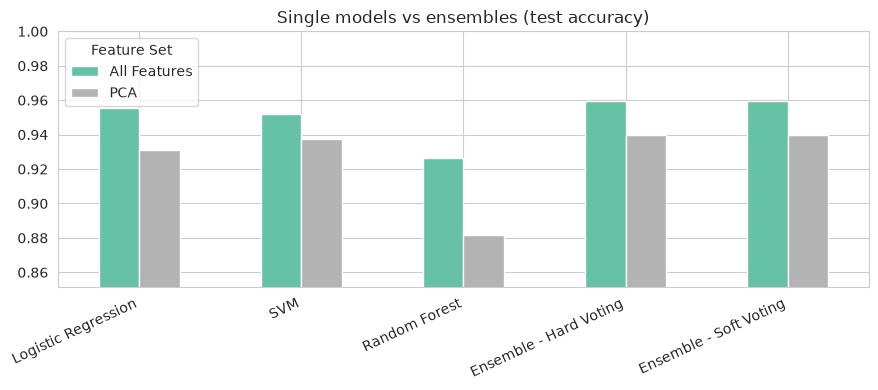

In [23]:
# Single models vs ensembles (accuracy)
all_df = pd.DataFrame(list(results.values()))
compare = ["Logistic Regression", "SVM", "Random Forest", "Ensemble - Hard Voting", "Ensemble - Soft Voting"]
comp = (all_df[all_df["Feature Set"].isin(["All Features", "PCA"]) & all_df["Model"].isin(compare)]
        .pivot(index="Model", columns="Feature Set", values="Accuracy").reindex(compare))
display(comp.round(4))

comp.plot(kind="bar", figsize=(9, 4), colormap="Set2", edgecolor="white")
plt.title("Single models vs ensembles (test accuracy)")
plt.ylim(max(0, comp.min().min() - 0.03), 1.0)
plt.xticks(rotation=25, ha="right")
plt.xlabel("")
plt.tight_layout()
plt.show()

## 11. Final Results & Comprehensive Leaderboard


,Feature Set,Model,Num Features,Accuracy,F1 (macro),Train Time (s)
1,All Features,Ensemble - Soft Voting,561,0.9596,0.9588,16.5988
2,All Features,Ensemble - Hard Voting,561,0.9593,0.9588,16.5988
3,All Features,Logistic Regression,561,0.9552,0.9551,9.6773
4,All Features,SVM,561,0.9518,0.9511,2.4304
5,PCA,Ensemble - Soft Voting,102,0.9399,0.9391,9.2062
6,PCA,Ensemble - Hard Voting,102,0.9396,0.9381,9.2062
7,PCA,SVM,102,0.9376,0.9362,0.6714
8,PCA,Logistic Regression,102,0.9311,0.9298,6.3241
9,All Features,Random Forest,561,0.9267,0.9251,0.8211
10,All Features,KNN,561,0.8836,0.8805,0.1839


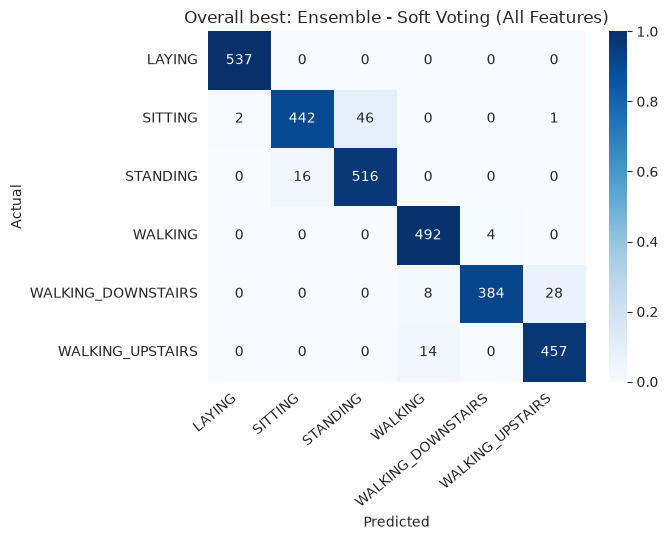

Features: 561 original -> 15 (forward/backward selection) -> 102 (PCA, 95% variance)
Overall best: Ensemble - Soft Voting on All Features -> accuracy 0.9596, F1 0.9588


In [24]:
# Top 10 experiments by macro F1
all_df = pd.DataFrame(list(results.values()))
board = (all_df.sort_values("F1 (macro)", ascending=False).head(10)
         [["Feature Set", "Model", "Num Features", "Accuracy", "F1 (macro)", "Train Time (s)"]].reset_index(drop=True))
board.index += 1
display(board.round(4))

# Confusion matrix of the overall best experiment
top = all_df.sort_values("F1 (macro)", ascending=False).iloc[0]
plot_confusion(y_test, predictions[(top["Feature Set"], top["Model"])], f"Overall best: {top['Model']} ({top['Feature Set']})")

print(f"Features: {X_train.shape[1]} original -> {n_select} (forward/backward selection) -> {n_pca} (PCA, {PCA_VARIANCE * 100:.0f}% variance)")
print(f"Overall best: {top['Model']} on {top['Feature Set']} -> accuracy {top['Accuracy']:.4f}, F1 {top['F1 (macro)']:.4f}")


### Final Project Conclusion & Findings

**Project by:** Kartikeya Jain & Ayush Yadav  
**Supervised by:** Dr. Pruthwik Mishra & Dr. Praveen Chandaliya  

- **Dataset & EDA:** 
  - Total 10,299 samples (7,352 train, 2,947 test) across 6 balanced activity classes with zero missing values and zero duplicate rows.
  - High multicollinearity was observed: 23.3% of feature pairs have correlation > 0.70 and 5.2% (8,206 pairs) have correlation > 0.90, justifying dimensionality reduction and feature selection.

- **Unsupervised Learning:**
  - **KMeans++ (k=2):** Naturally discovered the separation between Dynamic activities (WALKING, WALKING_UPSTAIRS, WALKING_DOWNSTAIRS) and Static activities (SITTING, STANDING, LAYING) with 99.7% alignment (silhouette score peaked at k=2).
  - **KMeans++ (k=6):** Achieved Adjusted Rand Index (ARI) of 0.420 and NMI of 0.559. Static activities (SITTING and STANDING) heavily overlapped in feature space.
  - **DBSCAN:** Formed 5 dense clusters and identified 371 isolated noise points (ARI = 0.320).

- **Dimensionality Reduction & Feature Selection:**
  - **PCA:** 102 principal components retained 95% of total variance (an 81.8% reduction from 561 original features).
  - **Sequential Feature Selection (SFS):** Selected just 15 features (11 shared by both forward and backward selection). Backward Selection with SVM reached **87.51% accuracy** using only 15 features.

- **Supervised Models & Cross-Validation:**
  - **Best Single Model:** Logistic Regression on All Features achieved **95.52% test accuracy** and **0.9551 macro F1**, closely followed by SVM (**95.18% accuracy**).
  - On PCA features (102 components), SVM achieved **93.76% accuracy** and trained in only 0.67 seconds.
  - 5-Fold Volunteer Group Cross-Validation confirmed generalizability across subjects (Logistic Regression: 91.89% ± 4.29%, SVM: 90.92% ± 4.40%).

- **Ensemble Performance:**
  - **Overall Best Model:** Soft Voting Ensemble (Logistic Regression + SVM + Random Forest) on All Features achieved the highest overall score: **95.96% accuracy** and **0.9588 macro F1**.
  - On PCA features, Soft Voting achieved **93.99% accuracy**.

- **Key Error Analysis:**
  - 53.8% of all test misclassifications (71 out of 132 mistakes) occurred strictly between **SITTING and STANDING**, as both produce nearly identical stationary gravity signals.
